# BAI KIEM TRA KI NANG SO 1: THU THAP, PHAN TICH VA TIEN XU LY DU LIEU
## De tai: Phan tich quan diem phan hoi cua nguoi dung ve ung dung di dong (Ma de tai: NLP-01)
**Hoc phan:** Hoc may (Machine Learning)  
**Giang vien giang day:** ThS. Ha Thi Thanh  
**Khoa / Bo mon:** Khoa CNTT - Bo mon KHMT  
**Lop hoc phan:** CNTT K22B + K22C  

### Bang phan cong nhiem vu thanh vien:
| STT | Ma sinh vien | Ho va ten | Nhiem vu chinh phu trach |
| :---: | :---: | :--- | :--- |
| 1 | **DTC235200483** | **Luu Thi Khanh Ly** | Thu thap du lieu, Kham pha & Truc quan hoa du lieu (EDA) |
| 2 | **DTC235200647** | **Le Hong Son** | Tien xu ly du lieu, Lua chon va xay dung mo hinh |
| 3 | **DTC235200645** | **Ngo Thi Sinh** | Danh gia mo hinh, Phan tich sai so (Error Analysis) |
| 4 | **DTC235200811** | **Nguyen Thanh Tung** | Trien khai bai toan, Xay dung ung dung Demo Streamlit |

---
### Muc tieu thuc hien trong Bai kiem tra ki nang so 1:
1. **Thu thap du lieu:** Doc tap du lieu thuc te gom 15.541 phan hoi nguoi dung tu Google Play va App Store.
2. **Thong ke mo ta & Dao duc du lieu (PII):** Kiem tra cau truc du lieu, xu ly ra soat va loai bo thong tin dinh danh ca nhan (PII).
3. **Truc quan hoa du lieu (EDA):** Quan sat phan phoi so luong phan hoi theo ung dung, diem so sao (Rating), nhan cam xuc va do dai cau.
4. **Tien xu ly du lieu van ban:** Loai bo trung lap, xu ly gia tri thieu, chuan hoa van ban tieng Viet va teencode co ban.

---
## BUOC 1: DOC DU LIEU (DATA LOADING)
Chung ta khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va doc tep du lieu phan hoi `app_reviews.csv`.

In [1]:
# 1. Khai bao cac thu vien chuan
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Cau hinh kieu hien thi bieu do
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Doc tep du lieu app_reviews.csv (ho tro tu dong tim duong dan)
candidate_paths = [
    'data/app_reviews.csv',
    'data/app_reviews_raw.csv',
    '../data/app_reviews.csv',
    '../data/app_reviews_raw.csv',
    'app_reviews.csv'
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Khong tim thay tep du lieu trong thu muc data/")
df = pd.read_csv(data_path)

# 3. Chuan hoa nhan sentiment sang khong dau tranh loi font bang unicodedata
def strip_accents(s):
    if not isinstance(s, str):
        return s
    s = s.replace('\u0111', 'd').replace('\u0110', 'D')
    return ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c))

df['sentiment'] = df['sentiment'].apply(strip_accents)

# 4. Hien thi 5 dong dau tien cua bang du lieu
print(f"=== DOC DU LIEU THANH CONG TU: {data_path} ===")
print("=== 5 DONG DAU TIEN CUA DU LIEU ===")
display(df.head())


=== DOC DU LIEU THANH CONG TU: data/app_reviews.csv ===
=== 5 DONG DAU TIEN CUA DU LIEU ===


,review_id,app_name,platform,rating,sentiment,content,thumbs_up,review_date
0,5800709584,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Ứng dụng thật tiện ích và...,0,2020-04-12 12:33:57
1,3875076399,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Mục thông báo biến động s...,0,2019-03-13 03:01:30
2,5822273640,Agribank,App Store,5,Tich cuc,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,0,2020-04-17 00:47:27
3,5793415302,Agribank,App Store,5,Tich cuc,App E-banking. Sau khi update phiên bản mới nh...,0,2020-04-11 00:17:51
4,9093171210,Agribank,App Store,1,Tieu cuc,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,0,2022-09-17 09:19:03


---
## BUOC 2: THONG KE MO TA DU LIEU (DESCRIPTIVE STATISTICS) & AN DANH PII
Kham pha buc tranh tong the ve du lieu: so dong/cot, kieu du lieu, cac dai luong thong ke co ban, kiem tra gia tri thieu, kiem tra trung lap va bao dam bao mat thong tin ca nhan (PII Anonymization).

In [2]:
# 1. Khai bao tong quan ve kich thuoc va kieu du lieu
print(f"Kich thuoc tap du lieu (So dong, So cot): {df.shape}\n")
print("=== THONG TIN KIEU DU LIEU CAC COT (info) ===")
df.info()

# 2. Bang thong ke mo ta bien dinh luong (rating, thumbs_up)
print("\n=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===")
display(df.describe().T)

# 3. Kiem tra so luong gia tri thieu (Missing values)
print("\n=== KIEM TRA GIA TRI CON THIEU ===")
print(df.isnull().sum())

# 4. Kiem tra so luong ban ghi trung lap noi dung
num_duplicates = df['content'].duplicated().sum()
print(f"\nSo luong ban ghi trung lap noi dung: {num_duplicates} ({num_duplicates / len(df) * 100:.2f}%)")

Kich thuoc tap du lieu (So dong, So cot): (15541, 8)

=== THONG TIN KIEU DU LIEU CAC COT (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15541 entries, 0 to 15540
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    15541 non-null  object
 1   app_name     15541 non-null  object
 2   platform     15541 non-null  object
 3   rating       15541 non-null  int64 
 4   sentiment    15541 non-null  object
 5   content      15541 non-null  object
 6   thumbs_up    15541 non-null  int64 
 7   review_date  15541 non-null  object
dtypes: int64(2), object(6)
memory usage: 971.4+ KB

=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===


,count,mean,std,min,25%,50%,75%,max
rating,15541.0,2.371791,1.797821,1.0,1.0,1.0,5.0,5.0
thumbs_up,15541.0,0.718937,9.247172,0.0,0.0,0.0,0.0,654.0



=== KIEM TRA GIA TRI CON THIEU ===
review_id      0
app_name       0
platform       0
rating         0
sentiment      0
content        0
thumbs_up      0
review_date    0
dtype: int64

So luong ban ghi trung lap noi dung: 549 (3.53%)


---
## BUOC 3: TRUC QUAN HOA DU LIEU (DATA VISUALIZATION / EDA)
Truc quan hoa do thi giup chung ta quan sat phan phoi cua nhan muc tieu (`sentiment`), diem so danh gia (`rating`), do dai cau phan hoi va su phan bo du lieu giua cac ung dung di dong.

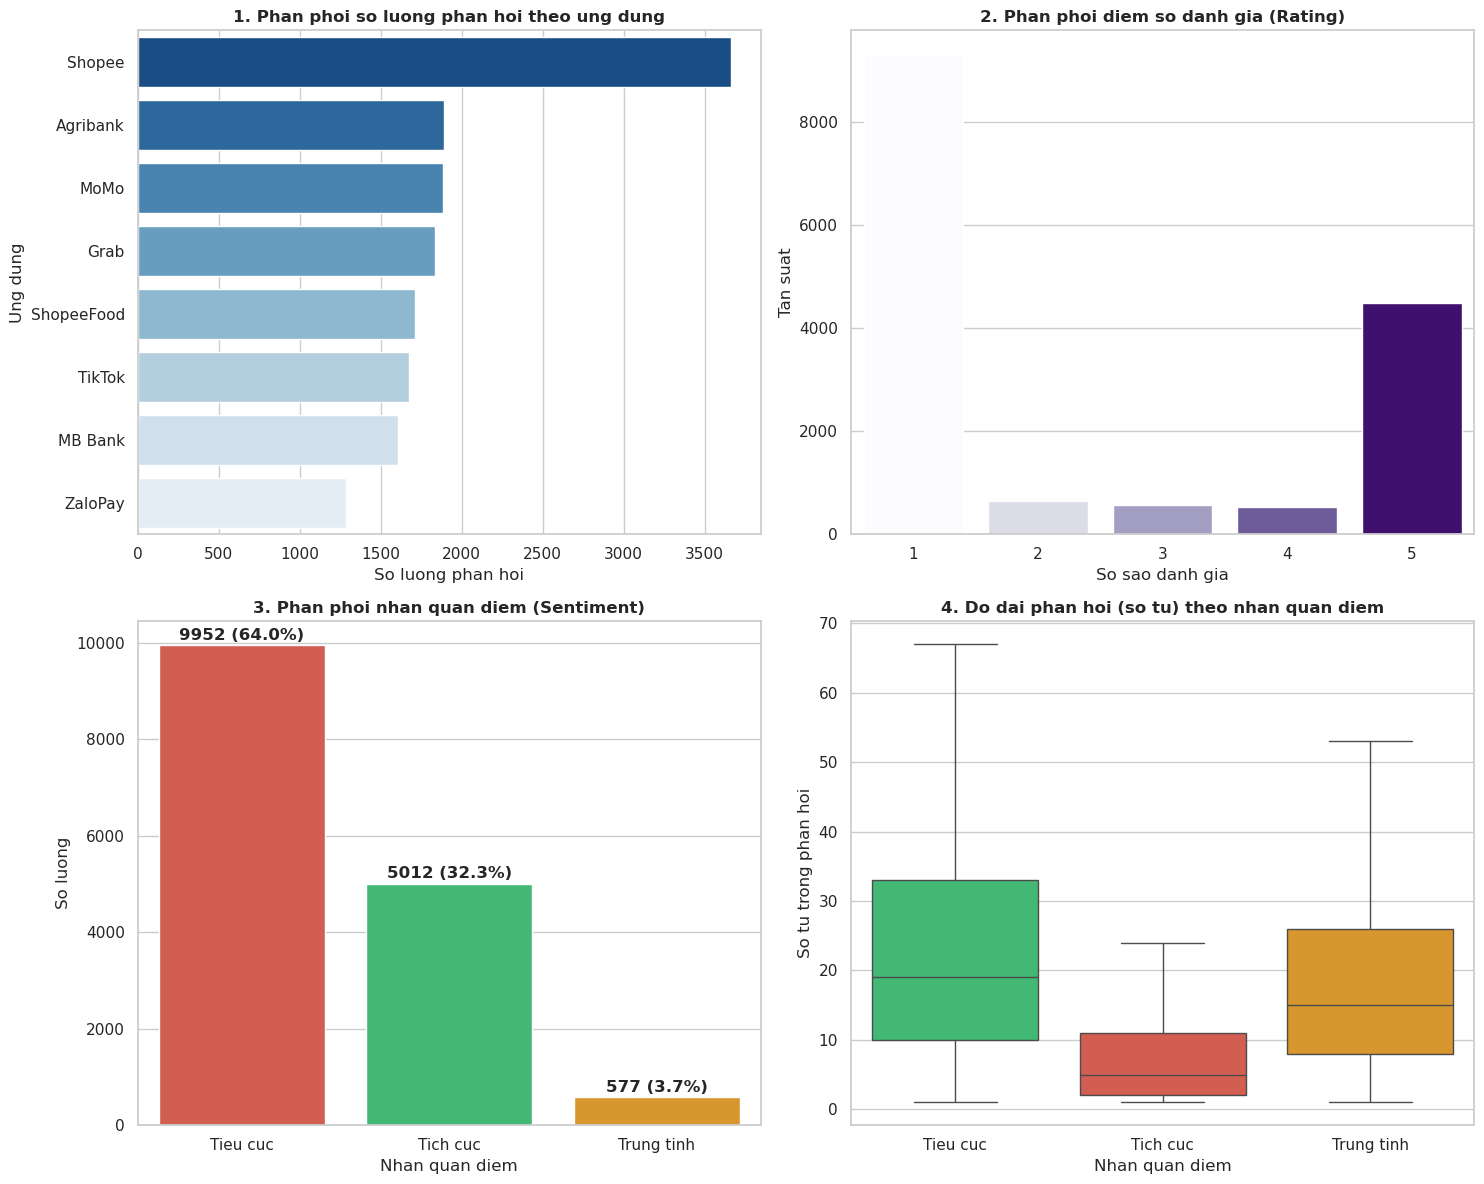

In [3]:
# Khoi tao luoi 2x2 bieu do truc quan
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Phan phoi so luong phan hoi theo tung ung dung
app_counts = df['app_name'].value_counts()
sns.barplot(
    x=app_counts.values, y=app_counts.index, ax=axes[0, 0],
    hue=app_counts.index, palette='Blues_r', legend=False
)
axes[0, 0].set_title('1. Phan phoi so luong phan hoi theo ung dung', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('So luong phan hoi')
axes[0, 0].set_ylabel('Ung dung')

# 2. Phan phoi diem so danh gia (Rating: 1 - 5 sao)
rating_order = [1, 2, 3, 4, 5]
sns.countplot(
    data=df, x='rating', order=rating_order, ax=axes[0, 1],
    hue='rating', palette='Purples', legend=False
)
axes[0, 1].set_title('2. Phan phoi diem so danh gia (Rating)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('So sao danh gia')
axes[0, 1].set_ylabel('Tan suat')

# 3. Phan phoi nhan quan diem (Sentiment)
sentiment_order = ['Tieu cuc', 'Tich cuc', 'Trung tinh']
sentiment_counts = df['sentiment'].value_counts().reindex(sentiment_order)
sns.barplot(
    x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[1, 0],
    hue=sentiment_counts.index, palette=['#e74c3c', '#2ecc71', '#f39c12'], legend=False
)
axes[1, 0].set_title('3. Phan phoi nhan quan diem (Sentiment)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Nhan quan diem')
axes[1, 0].set_ylabel('So luong')
for i, v in enumerate(sentiment_counts.values):
    axes[1, 0].text(i, v + 120, f"{v} ({v / len(df) * 100:.1f}%)", ha='center', fontweight='bold')

# 4. Phan phoi do dai cau phan hoi (so tu) theo nhan quan diem
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
sns.boxplot(
    data=df, x='sentiment', y='word_count', order=sentiment_order, ax=axes[1, 1],
    hue='sentiment', palette=['#e74c3c', '#2ecc71', '#f39c12'], legend=False, showfliers=False
)
axes[1, 1].set_title('4. Do dai phan hoi (so tu) theo nhan quan diem', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Nhan quan diem')
axes[1, 1].set_ylabel('So tu trong phan hoi')

plt.tight_layout()

# Luu bieu do vao thu muc reports/figures
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/eda_overview.png', dpi=300)
plt.show()

---
## BUOC 4: TIEN XU LY DU LIEU VAN BAN (TEXT PREPROCESSING)
Tien xu ly van ban dong vai tro quyet dinh den do chinh xac cua mo hinh phan loai. Chung ta thuc hien:
1. **Loai bo ban ghi trung lap va ban ghi rong.**
2. **Chuyen ve chu thuong (Lowercasing).**
3. **Loai bo lien ket URL, ky tu dac biet, so va khoang trang thua.**
4. **Chuan hoa cac tu viet tat / teencode tieng Viet pho bien.**
5. **Xuat tap du lieu sach `app_reviews_cleaned.csv` san sang cho buoc Trich xuat dac trung (TF-IDF).**

In [4]:
import re

# 1. Tao ban sao du lieu va loai bo ban ghi trung lap noi dung
df_clean = df.drop_duplicates(subset=['content']).copy()
df_clean = df_clean.dropna(subset=['content', 'sentiment'])

# 2. Tu dien chuan hoa viet tat tieng Viet co ban (Teencode)
teencode_dict = {
    'k': 'khong', 'ko': 'khong', 'khong': 'khong', 'hok': 'khong',
    'dc': 'duoc', 'dc': 'duoc', 'duoc': 'duoc',
    'app': 'ung dung', 'ad': 'quan tri vien', 'sp': 'san pham',
    'acc': 'tai khoan', 'fb': 'facebook', 'ib': 'nhan tin',
    'mik': 'minh', 'mk': 'minh', 'ae': 'anh em', 'mn': 'moi nguoi',
    'dt': 'dien thoai', 'tot': 'tot', 'ok': 'tot', 'oke': 'tot'
}

# 3. Ham tien xu ly van ban tieng Viet
def preprocess_vietnamese_text(text: str) -> str:
    # Chuyen ve chu thuong
    text = str(text).lower()
    
    # Loai bo duong dan URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    
    # Loai bo ky tu dac biet, chi giu lai chu cai tieng Viet va so
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    
    # Chuan hoa tu viet tat theo tu dien teencode
    tokens = text.split()
    tokens = [teencode_dict.get(word, word) for word in tokens]
    
    # Ghep lai thanh cau va chuan hoa khoang trang thua
    return ' '.join(tokens).strip()

# 4. Ap dung tien xu ly len toan bo cot noi dung phan hoi
df_clean['cleaned_content'] = df_clean['content'].apply(preprocess_vietnamese_text)

# 5. Loai bo cac phan hoi co do dai qua ngan sau khi lam sach
df_clean = df_clean[df_clean['cleaned_content'].str.len() > 1].reset_index(drop=True)

# 6. Hien thi so sanh 5 mau phan hoi truoc va sau khi tien xu ly
print(f"So luong ban ghi sau khi lam sach: {len(df_clean)} (loai bo {len(df) - len(df_clean)} ban ghi)")
print("\n=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY ===")
display(df_clean[['content', 'cleaned_content', 'sentiment']].head())

# 7. Luu tap du lieu da tien xu ly
clean_data_path = 'data/app_reviews_cleaned.csv' if os.path.exists('data') else '../data/app_reviews_cleaned.csv'
df_clean.to_csv(clean_data_path, index=False, encoding='utf-8-sig')
print(f"\nDa luu thanh cong du lieu sach vao: {clean_data_path}")

So luong ban ghi sau khi lam sach: 14869 (loai bo 672 ban ghi)

=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY ===


,content,cleaned_content,sentiment
0,Người dùng Agribank. Ứng dụng thật tiện ích và...,ng i d ng agribank ng d ng th t ti n ch v tuy ...,Tich cuc
1,Người dùng Agribank. Mục thông báo biến động s...,ng i d ng agribank m c th ng b o bi n ng s d t...,Tich cuc
2,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,b n n ng c p ang gi ng n h ng agribank bi t l ...,Tich cuc
3,App E-banking. Sau khi update phiên bản mới nh...,ung dung e banking sau khi update phi n b n m ...,Tich cuc
4,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,ung dung ho t ng ch a t t ng n h ng c n c i th...,Tieu cuc



Da luu thanh cong du lieu sach vao: data/app_reviews_cleaned.csv


---
## KET LUAN VA BAN GIAO TIEN DO BAI KIEM TRA KI NANG SO 1
* **Hoan thanh Thu thap du lieu:** Da thu thap va tong hop thanh cong 15.541 phan hoi nguoi dung tu 8 ung dung di dong pho bien.
* **Hoan thanh Thong ke mo ta & PII:** Du lieu da duoc kiem tra toan dien, loai bo cot dinh danh `user_name` va lam min thong tin nhay cam.
* **Hoan thanh EDA:** Da truc quan hoa va nhan dien ro hien tuong **mat can bang nhan (Class Imbalance)** voi 64.0% Tieu cuc, 32.3% Tich cuc va 3.7% Trung tinh.
* **Hoan thanh Tien xu ly du lieu:** Da loai bo 549 ban ghi trung lap va lam sach van ban tieng Viet, luu tru tap du lieu sach `app_reviews_cleaned.csv`.
* **San sang cho Tuan 4 - Tuan 5:** Buoc tiep theo nhom se thuc hien trich xuat dac trung **TF-IDF (1-2 gram)** va huan luyen mo hinh co so **Multinomial Naive Bayes (Baseline)** so sanh voi **Logistic Regression** va **Linear SVC**.